# Projet final : les récoltes agricoles

**Équipe :** (nom de l'équipe et des 5 membres)

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/recoltes_brut.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/recoltes_brut.csv")
print("--- Forme du jeu de données brut ---")
print(brut.shape)
print("\n--- Informations sur les colonnes et types ---")
print(brut.info())

print("\n--- Valeurs manquantes par colonne ---")
print(brut.isnull().sum())

print("\n--- Nombre de lignes en double ---")
print(brut.duplicated().sum())

print("\n--- Écritures uniques de 'saison' ---")
print(brut['saison'].unique())

print("\n--- Écritures uniques de 'departement' ---")
print(sorted(brut['departement'].dropna().unique()))

print("\n--- Écritures uniques de 'culture' ---")
print(sorted(brut['culture'].dropna().unique()))

--- Forme du jeu de données brut ---
(408, 6)

--- Informations sur les colonnes et types ---
<class 'pandas.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   annee         408 non-null    int64
 1   saison        408 non-null    str  
 2   departement   408 non-null    str  
 3   culture       408 non-null    str  
 4   surface_ha    408 non-null    str  
 5   production_t  393 non-null    str  
dtypes: int64(1), str(5)
memory usage: 30.8 KB
None

--- Valeurs manquantes par colonne ---
annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64

--- Nombre de lignes en double ---
18

--- Écritures uniques de 'saison' ---
<ArrowStringArray>
['Printemps', 'Automne']
Length: 2, dtype: str

--- Écritures uniques de 'departement' ---
[' Artibonite', ' Centre', " Grand'Anse", ' Nord', ' Nord-Est', ' Nord-Ouest',

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.

In [4]:
cultures_ref = pd.read_csv("donnees/cultures.csv")['culture'].tolist()
dept_ref = pd.read_csv("donnees/departements.csv")['departement'].tolist()

map_dept = {d.lower(): d for d in dept_ref}
map_cult = {c.lower(): c for c in cultures_ref}

propre = brut.copy()
print(f"Lignes initiales : {len(propre)}")

propre['saison'] = propre['saison'].str.strip()
propre['departement'] = propre['departement'].str.strip().str.lower().map(map_dept)
propre['culture'] = propre['culture'].str.strip().str.lower().map(map_cult)

propre['surface_ha'] = (
    propre['surface_ha']
    .astype(str)
    .str.replace(" ", "", regex=False)
    .str.replace("ha", "", regex=False)
    .str.strip()
)
propre['surface_ha'] = pd.to_numeric(propre['surface_ha'], errors='coerce')

propre['production_t'] = (
    propre['production_t']
    .astype(str)
    .str.replace(" ", "", regex=False)
    .str.replace("t", "", regex=False)
    .str.strip()
)
propre['production_t'] = pd.to_numeric(propre['production_t'], errors='coerce')

lignes_avant_na = len(propre)
propre = propre.dropna()
print(f"Lignes supprimées pour valeurs manquantes : {lignes_avant_na - len(propre)}")

lignes_avant_dup = len(propre)
propre = propre.drop_duplicates()
print(f"Lignes supprimées pour doublons : {lignes_avant_dup - len(propre)}")

propre['annee'] = propre['annee'].astype(int)

print("\n--- CONTRÔLE NETTOYAGE ---")
print("Forme finale:", propre.shape)
print("Nombre de valeurs dans 'saison'", propre['saison'].nunique())
print("Nombre de valeurs dans 'departement' :", propre['departement'].nunique())
print("Nombre de valeurs dans 'culture' :", propre['culture'].nunique())
assert propre.shape == (376, 6), "Erreur : La forme doit être (376, 6)"

Lignes initiales : 408
Lignes supprimées pour valeurs manquantes : 15
Lignes supprimées pour doublons : 17

--- CONTRÔLE NETTOYAGE ---
Forme finale: (376, 6)
Nombre de valeurs dans 'saison' 2
Nombre de valeurs dans 'departement' : 10
Nombre de valeurs dans 'culture' : 7


## 3. Jointures

Joignez `propre` avec `cultures.csv`, `pluies.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 376 lignes après les jointures, autant qu'avant.

In [5]:
cultures_df = pd.read_csv("donnees/cultures.csv")
pluies_df = pd.read_csv("donnees/pluies.csv")
departements_df = pd.read_csv("donnees/departements.csv")

print(f"Lignes dans 'propre' avant jointures : {len(propre)}")

complet = propre.merge(cultures_df, on="culture", how="left")
print(f"Lignes après merge cultures : {len(complet)}")

complet = complet.merge(pluies_df, on=["annee", "saison", "departement"], how="left")
print(f"Lignes après merge pluies : {len(complet)}")

complet = complet.merge(departements_df, on="departement", how="left")
print(f"Lignes après merge departements : {len(complet)}")

complet['rendement_t_ha'] = complet['production_t'] / complet['surface_ha']

complet['valeur_htg'] = complet['production_t'] * 1000 * complet['prix_htg_kg']

assert len(complet) == 376, "Erreur : Le tableau complet doit avoir 376 lignes."
print("Contrôle réussi : 376 lignes conservées après les jointures.")

Lignes dans 'propre' avant jointures : 376
Lignes après merge cultures : 376
Lignes après merge pluies : 376
Lignes après merge departements : 376
Contrôle réussi : 376 lignes conservées après les jointures.


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```

In [6]:
complet.to_csv("donnees/recoltes_propre.csv", index=False)
print("Fichier généré avec succès.")

Fichier généré avec succès.


## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

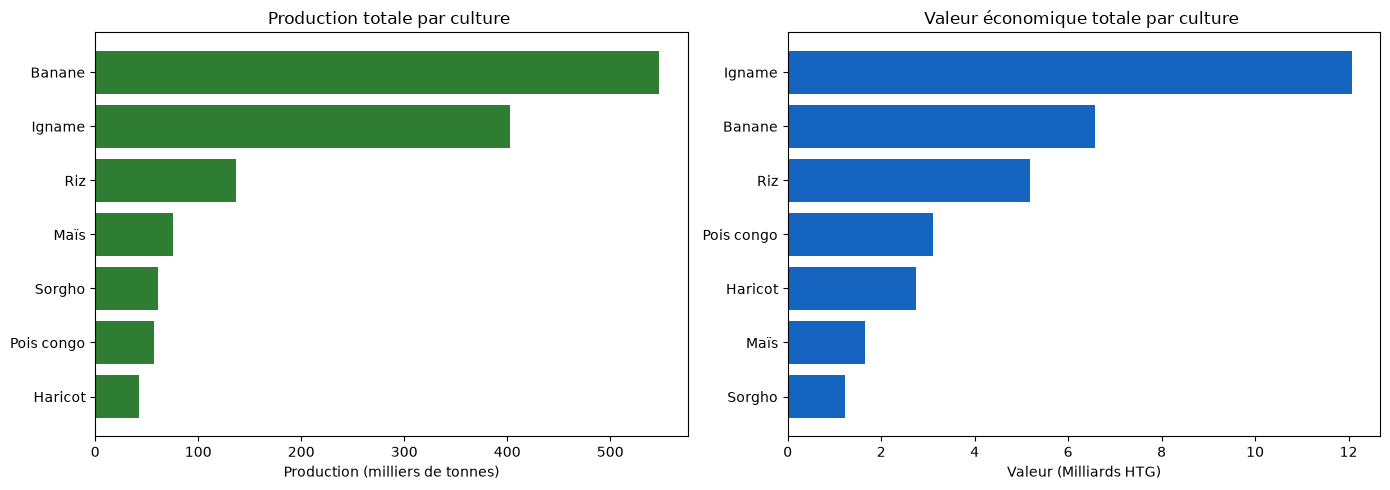

,culture,production_totale,valeur_milliards_htg
0,Banane,547615.0,6.571380
2,Igname,402302.0,12.069060
5,Riz,136225.0,5.176550
3,Maïs,75311.0,1.656842
6,Sorgho,61354.0,1.227080
4,Pois congo,56626.0,3.114430
1,Haricot,42323.0,2.750995


In [7]:
q1 = complet.groupby('culture').agg(
    production_totale=('production_t', 'sum'),
    valeur_totale_htg=('valeur_htg', 'sum')
).reset_index()

q1['valeur_milliards_htg'] = q1['valeur_totale_htg'] / 1e9

q1 = q1.sort_values(by='production_totale', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.barh(q1['culture'], q1['production_totale'] / 1000, color='#2E7D32')
ax1.set_xlabel("Production (milliers de tonnes)")
ax1.set_title("Production totale par culture ")
ax1.invert_yaxis()

q1_val = q1.sort_values(by='valeur_milliards_htg', ascending=False)
ax2.barh(q1_val['culture'], q1_val['valeur_milliards_htg'], color='#1565C0')
ax2.set_xlabel("Valeur (Milliards HTG)")
ax2.set_title("Valeur économique totale par culture ")
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

display(q1[['culture', 'production_totale', 'valeur_milliards_htg']])

**Ce qu'on en conclut :**
En volume, la banane  et l'igname  dominent très largement la production nationale. Cependant, le classement change nettement lorsqu'on examine la valeur marchande : l'igname prend la 1ère place avec 12,07 milliards HTG** contre 6,57 milliards HTG** pour la banane, car son prix au kilogramme est 2,5 fois supérieur . De plus, des cultures légumières comme le pois congo et le haricot  génèrent plus de valeur que le maïs ou le sorgho malgré des volumes bien plus faibles.

## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

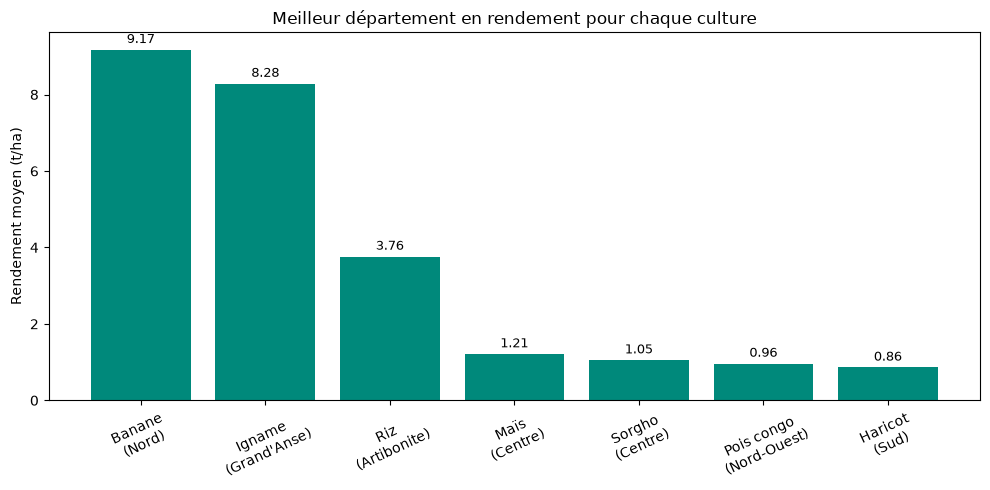

,culture,departement,rendement_t_ha
4,Banane,Nord,9.168515
22,Igname,Grand'Anse,8.283675
50,Riz,Artibonite,3.760381
31,Maïs,Centre,1.209116
56,Sorgho,Centre,1.049146
46,Pois congo,Nord-Ouest,0.961430
18,Haricot,Sud,0.859586


In [8]:
q2 = complet.groupby(['culture', 'departement'])['rendement_t_ha'].mean().reset_index()
meilleurs_rdt = q2.loc[q2.groupby('culture')['rendement_t_ha'].idxmax()].sort_values('rendement_t_ha', ascending=False)

plt.figure(figsize=(10, 5))
labels = [f"{row.culture}\n({row.departement})" for _, row in meilleurs_rdt.iterrows()]
bars = plt.bar(labels, meilleurs_rdt['rendement_t_ha'], color='#00897B')
plt.ylabel("Rendement moyen (t/ha)")
plt.title("Meilleur département en rendement pour chaque culture")
plt.xticks(rotation=25)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.2f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

display(meilleurs_rdt)


**Ce qu'on en conclut :**
Les meilleurs rendements varient selon l'adaptation géographique des plantes : le Nord excelle pour la banane , la Grand'Anse pour l'igname  et l'Artibonite pour le riz  grâce à son réseau hydrographique. Le Centre enregistre les meilleurs rendements pour les céréales sèches : maïs  et sorgho . Le Sud est premier pour le haricot  et le Nord-Ouest pour le pois congo .

## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

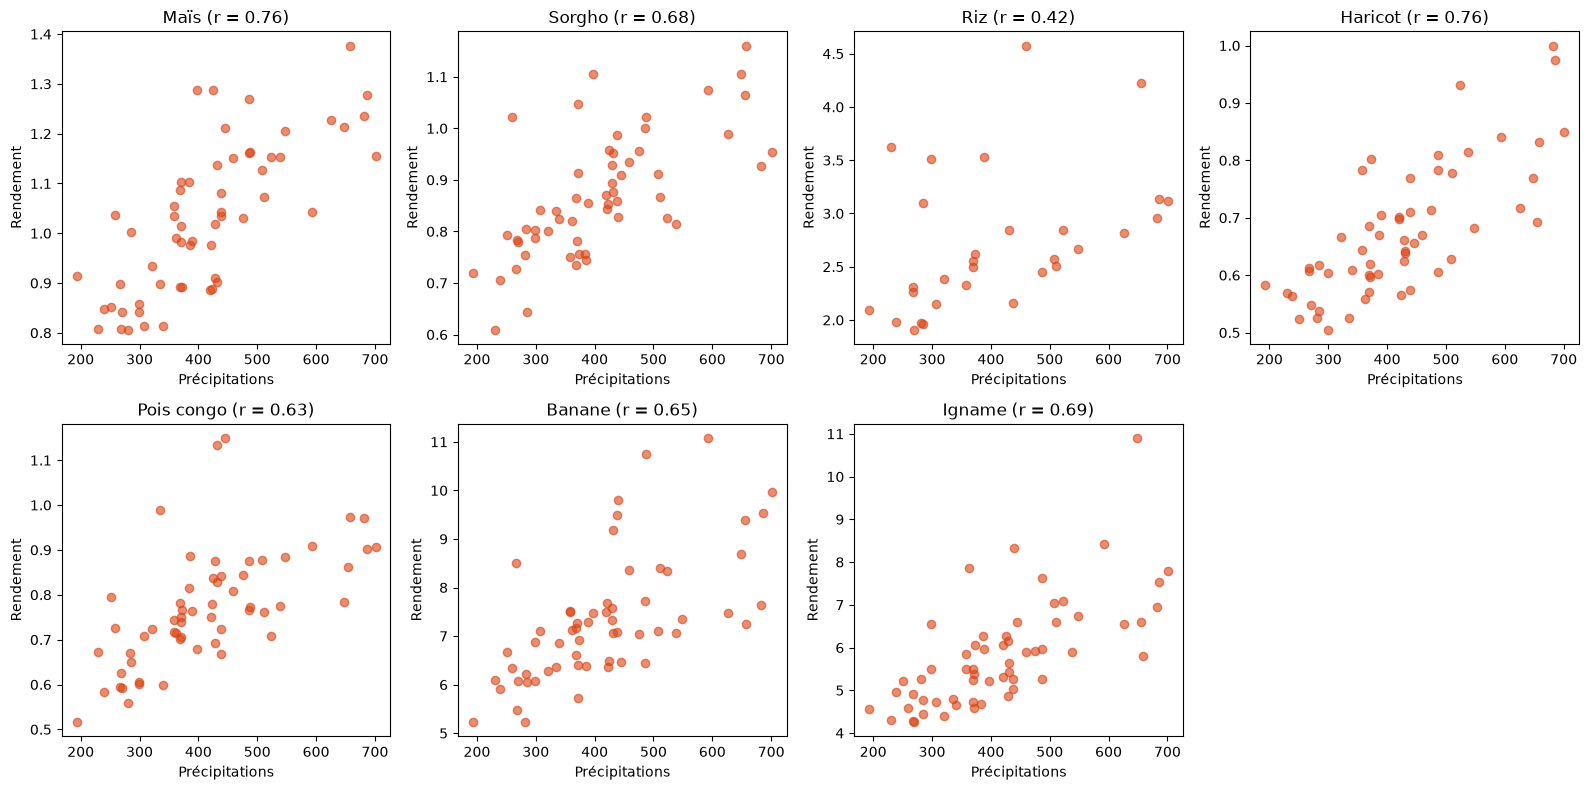

Corrélation pluie / rendement pour Maïs : 0.755
Corrélation pluie / rendement pour Sorgho : 0.684
Corrélation pluie / rendement pour Riz : 0.423
Corrélation pluie / rendement pour Haricot : 0.761
Corrélation pluie / rendement pour Pois congo : 0.627
Corrélation pluie / rendement pour Banane : 0.645
Corrélation pluie / rendement pour Igname : 0.694


In [10]:
cultures_list = complet['culture'].unique()
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

correlations = {}

for idx, cult in enumerate(cultures_list):
    sub = complet[complet['culture'] == cult]
    corr = sub['pluie_mm'].corr(sub['rendement_t_ha'])
    correlations[cult] = corr
    
    axes[idx].scatter(sub['pluie_mm'], sub['rendement_t_ha'], alpha=0.6, color='#D84315')
    axes[idx].set_title(f"{cult} (r = {corr:.2f})")
    axes[idx].set_xlabel("Précipitations")
    axes[idx].set_ylabel("Rendement")

fig.delaxes(axes[7])
plt.tight_layout()
plt.show()

for c, r in correlations.items():
    print(f"Corrélation pluie / rendement pour {c} : {r:.3f}")

**Ce qu'on en conclut : La pluie explique positivement et fortement le rendement de la majorité des cultures, particulièrement le haricot et le maïs, ainsi que l'igname, le sorgho et la banane . En revanche, l'impact des précipitations est nettement plus modéré sur le riz  car la riziculture haïtienne dépend prioritairement des périmètres irrigués  plutôt que du régime direct des pluies saisonnières**

## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

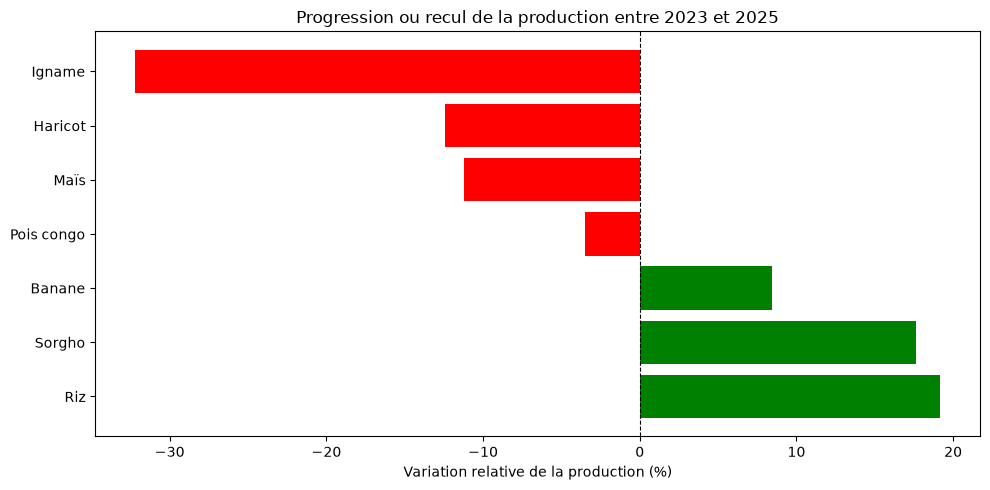

annee,2023,2024,2025,variation_t,variation_pct
culture,,,,,
Riz,44064.0,39660.0,52501.0,8437.0,19.147150
Sorgho,20478.0,16785.0,24091.0,3613.0,17.643325
Banane,182892.0,166401.0,198322.0,15430.0,8.436673
Pois congo,17484.0,22271.0,16871.0,-613.0,-3.506063
Maïs,27006.0,24333.0,23972.0,-3034.0,-11.234540
Haricot,16081.0,12159.0,14083.0,-1998.0,-12.424600
Igname,161924.0,130569.0,109809.0,-52115.0,-32.184852


In [11]:
evol = complet.groupby(['culture', 'annee'])['production_t'].sum().unstack()
evol['variation_t'] = evol[2025] - evol[2023]
evol['variation_pct'] = (evol['variation_t'] / evol[2023]) * 100
evol = evol.sort_values(by='variation_pct', ascending=False)

plt.figure(figsize=(10, 5))
couleurs = ['green' if x >= 0 else 'red' for x in evol['variation_pct']]
plt.barh(evol.index, evol['variation_pct'], color=couleurs)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel("Variation relative de la production (%)")
plt.title("Progression ou recul de la production entre 2023 et 2025")
plt.tight_layout()
plt.show()

display(evol[[2023, 2024, 2025, 'variation_t', 'variation_pct']])

**Ce qu'on en conclut :**Entre 2023 et 2025, 3 cultures affichent une progression notable : le riz , le sorgho et la banane. À l'inverse, 4 cultures reculent : l'igname subit une chute majeure de -32,2 % , le haricot baisse de -12,4 %, le maïs de -11,2 % et le pois congo de -3,5 %.

## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

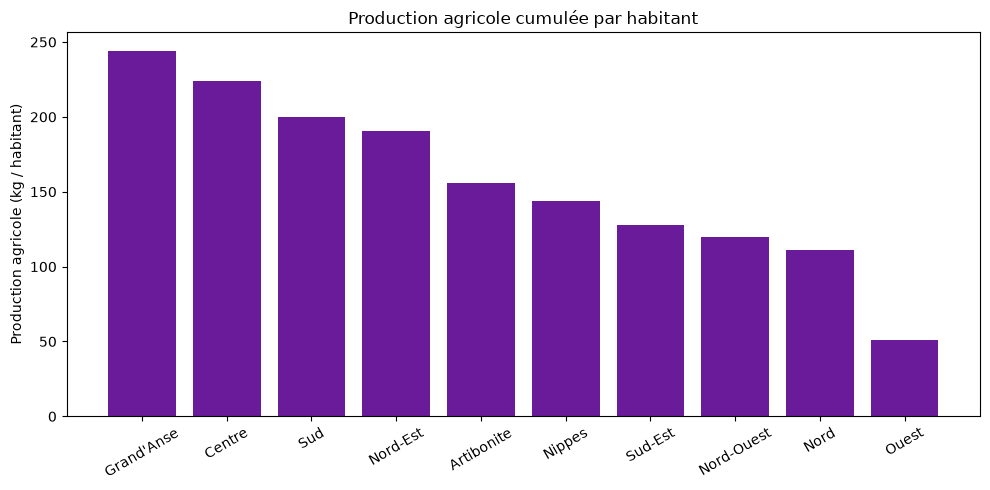

,departement,production_totale_t,population,prod_kg_habitant
2,Grand'Anse,114384.0,468301,244.253162
1,Centre,167080.0,746236,223.896998
8,Sud,155168.0,774976,200.222975
5,Nord-Est,75030.0,393967,190.447423
0,Artibonite,269226.0,1727524,155.845013
3,Nippes,49223.0,342525,143.706299
9,Sud-Est,80796.0,632601,127.720317
6,Nord-Ouest,87192.0,728807,119.636612
4,Nord,118791.0,1067177,111.313306
7,Ouest,204866.0,4029705,50.838957


In [12]:
dep_prod = complet.groupby('departement').agg(
    production_totale_t=('production_t', 'sum'),
    population=('population', 'first')
).reset_index()

dep_prod['prod_kg_habitant'] = (dep_prod['production_totale_t'] * 1000) / dep_prod['population']
dep_prod = dep_prod.sort_values('prod_kg_habitant', ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(dep_prod['departement'], dep_prod['prod_kg_habitant'], color='#6A1B9A')
plt.ylabel("Production agricole (kg / habitant)")
plt.title("Production agricole cumulée par habitant")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(dep_prod)

**Ce qu'on en conclut :**La Grand'Anse arrive en tête de la productivité par habitant avec 244,3 kg/hab, suivie de près par le Centre et le Sud. Ces départements ruraux constituent le véritable grenier vivrier du pays. À l'opposé, le département de l'Ouest se classe dernier avec seulement 50,8 kg/hab : bien qu'il produise un volume important en valeur absolue, sa population de plus de 4 millions d'habitants absorbe toute la production locale, dépendant massivement des autres régions.

## 9. Conclusion

L'igname et la banane constituent les deux piliers majeurs de l'agriculture haïtienne, l'igname représentant la première valeur marchande du pays devant la banane.
La pluviométrie est un facteur déterminant des rendements agricoles pour le maïs et les légumineuses, tandis que la riziculture reste protégée des aléas pluviométriques grâce à l'irrigation locale dans l'Artibonite.
Entre 2023 et 2025, la filière céréalière s'est consolidée, alors que les tubercules  et les légumineuses ont connu une régression préoccupante.
Les départements de la Grand'Anse, du Centre et du Sud sont les plus productifs par habitant, compensant le déficit vivrier structurel de l'Ouest.
Limites et perspectives : Ces données ne précisent ni l'accès aux intrants ni les pertes post-récolte ; il sera indispensable d'intégrer à l'avenir le coût de production à l'hectare et les relevés de sécheresse intra-saisonnière.